<a href="https://colab.research.google.com/github/ks-orintis/machine-learning/blob/main/%D0%9B%D0%A04_%D0%9B%D1%83%D1%87%D0%B0%D0%BD%D1%96%D0%BD%D0%BE%D0%B2%D0%B0_%D0%9A%D1%81%D0%B5%D0%BD%D1%96%D1%8F_%D0%A4%D0%86%D0%A2_4_8_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


In [33]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import os

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [34]:
path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
df = pd.read_csv(os.path.join(path, "CarPrice_Assignment.csv"))

display(df.head())

Using Colab cache for faster access to the 'car-price-prediction' dataset.


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


**car_ID** - Унікальний ідентифікатор автомобіля

**symboling** - Категорія страхового ризику автомобіля

**CarName** - Марка та модель автомобіля

**fueltype** - Тип пального (бензин або дизель)

**aspiration** - Тип подачі повітря до двигуна (стандартний або турбований)

**doornumber** - Кількість дверей автомобіля

**carbody** - Тип кузова автомобіля

**drivewheel** - Тип приводу (передній, задній або повний)

**enginelocation** - Розташування двигуна (спереду або ззаду)

**wheelbase** - Колісна база автомобіля

**carlength** - Довжина автомобіля

**carwidth** - Ширина автомобіля

**carheight** - Висота автомобіля

**curbweight** - Споряджена маса автомобіля

**enginetype** - Тип двигуна

**cylindernumber** - Кількість циліндрів двигуна

**enginesize** - Робочий об'єм двигуна

**fuelsystem** - Тип паливної системи

**boreratio** - Діаметр циліндра двигуна

**stroke** - Хід поршня

**compressionratio** - Ступінь стиснення двигуна

**horsepower** - Потужність двигуна в кінських силах

**peakrpm** - Частота обертання двигуна за максимальної потужності

**citympg** - Економічність пального в міському циклі (миль на галон)

**highwaympg** - Економічність пального на трасі (миль на галон)

**price** - Ціна автомобіля (цільова змінна для прогнозування)

In [35]:
df.shape

(205, 26)

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [37]:
display(df.describe())

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


Датасет містить 205 записів і 26 стовпців із числовими та категоріальними даними. Цільовою змінною є price — ціна автомобіля, яку необхідно прогнозувати.

## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [38]:
print("Кількість пропущених значень:")
display(df.isna().sum().sort_values(ascending=False))

print("Повні дублікати:", df.duplicated().sum())

print(
    "Дуплікати без урахування car_ID:",
    df.drop(columns="car_ID").duplicated().sum()
)

print("Кількість унікальних значень:")
display(df.nunique())

Кількість пропущених значень:


,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


Повні дублікати: 0
Дуплікати без урахування car_ID: 0
Кількість унікальних значень:


,0
car_ID,205
symboling,6
CarName,147
fueltype,2
aspiration,2
doornumber,2
carbody,5
drivewheel,3
enginelocation,2
wheelbase,53


У датасеті не виявлено пропущених значень і дублікатів, зокрема після виключення car_ID. Отже, дані не потребують додаткового очищення від пропусків і повторюваних записів.

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [39]:
df['CarName'].value_counts()

,count
CarName,
peugeot 504,6
toyota corolla,6
toyota corona,6
subaru dl,4
mitsubishi outlander,3
...,...
volkswagen super beetle,1
volkswagen rabbit custom,1
volvo 245,1


In [40]:
ids = df["car_ID"].copy()

df_model = df.copy()
df_model["brand"] = (
    df_model["CarName"]
    .str.lower()
    .str.split()
    .str[0]
    .replace({
        "maxda": "mazda",
        "porcshce": "porsche",
        "toyouta": "toyota",
        "vokswagen": "volkswagen",
        "vw": "volkswagen"
    })
)

df_model = df_model.drop(columns=["car_ID", "CarName"])

In [41]:
df_model

,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,brand
0,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,alfa-romero
1,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,alfa-romero
2,1,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,alfa-romero
3,2,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,2,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,...,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0,volvo
201,-1,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.8,...,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0,volvo
202,-1,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,...,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0,volvo
203,-1,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,...,idi,3.01,3.40,23.0,106,4800,26,27,22470.0,volvo


Ідентифікатори автомобілів збережено окремо та виключено з набору ознак для моделювання. Також із CarName виділено марку автомобіля, що дозволяє використовувати її як окрему категоріальну ознаку.

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


In [42]:
numeric_initial = df_model.select_dtypes(include=np.number).columns
skew_initial = df_model[numeric_initial].skew().sort_values(key=np.abs, ascending=False)
display(skew_initial.to_frame("skewness"))

,skewness
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997


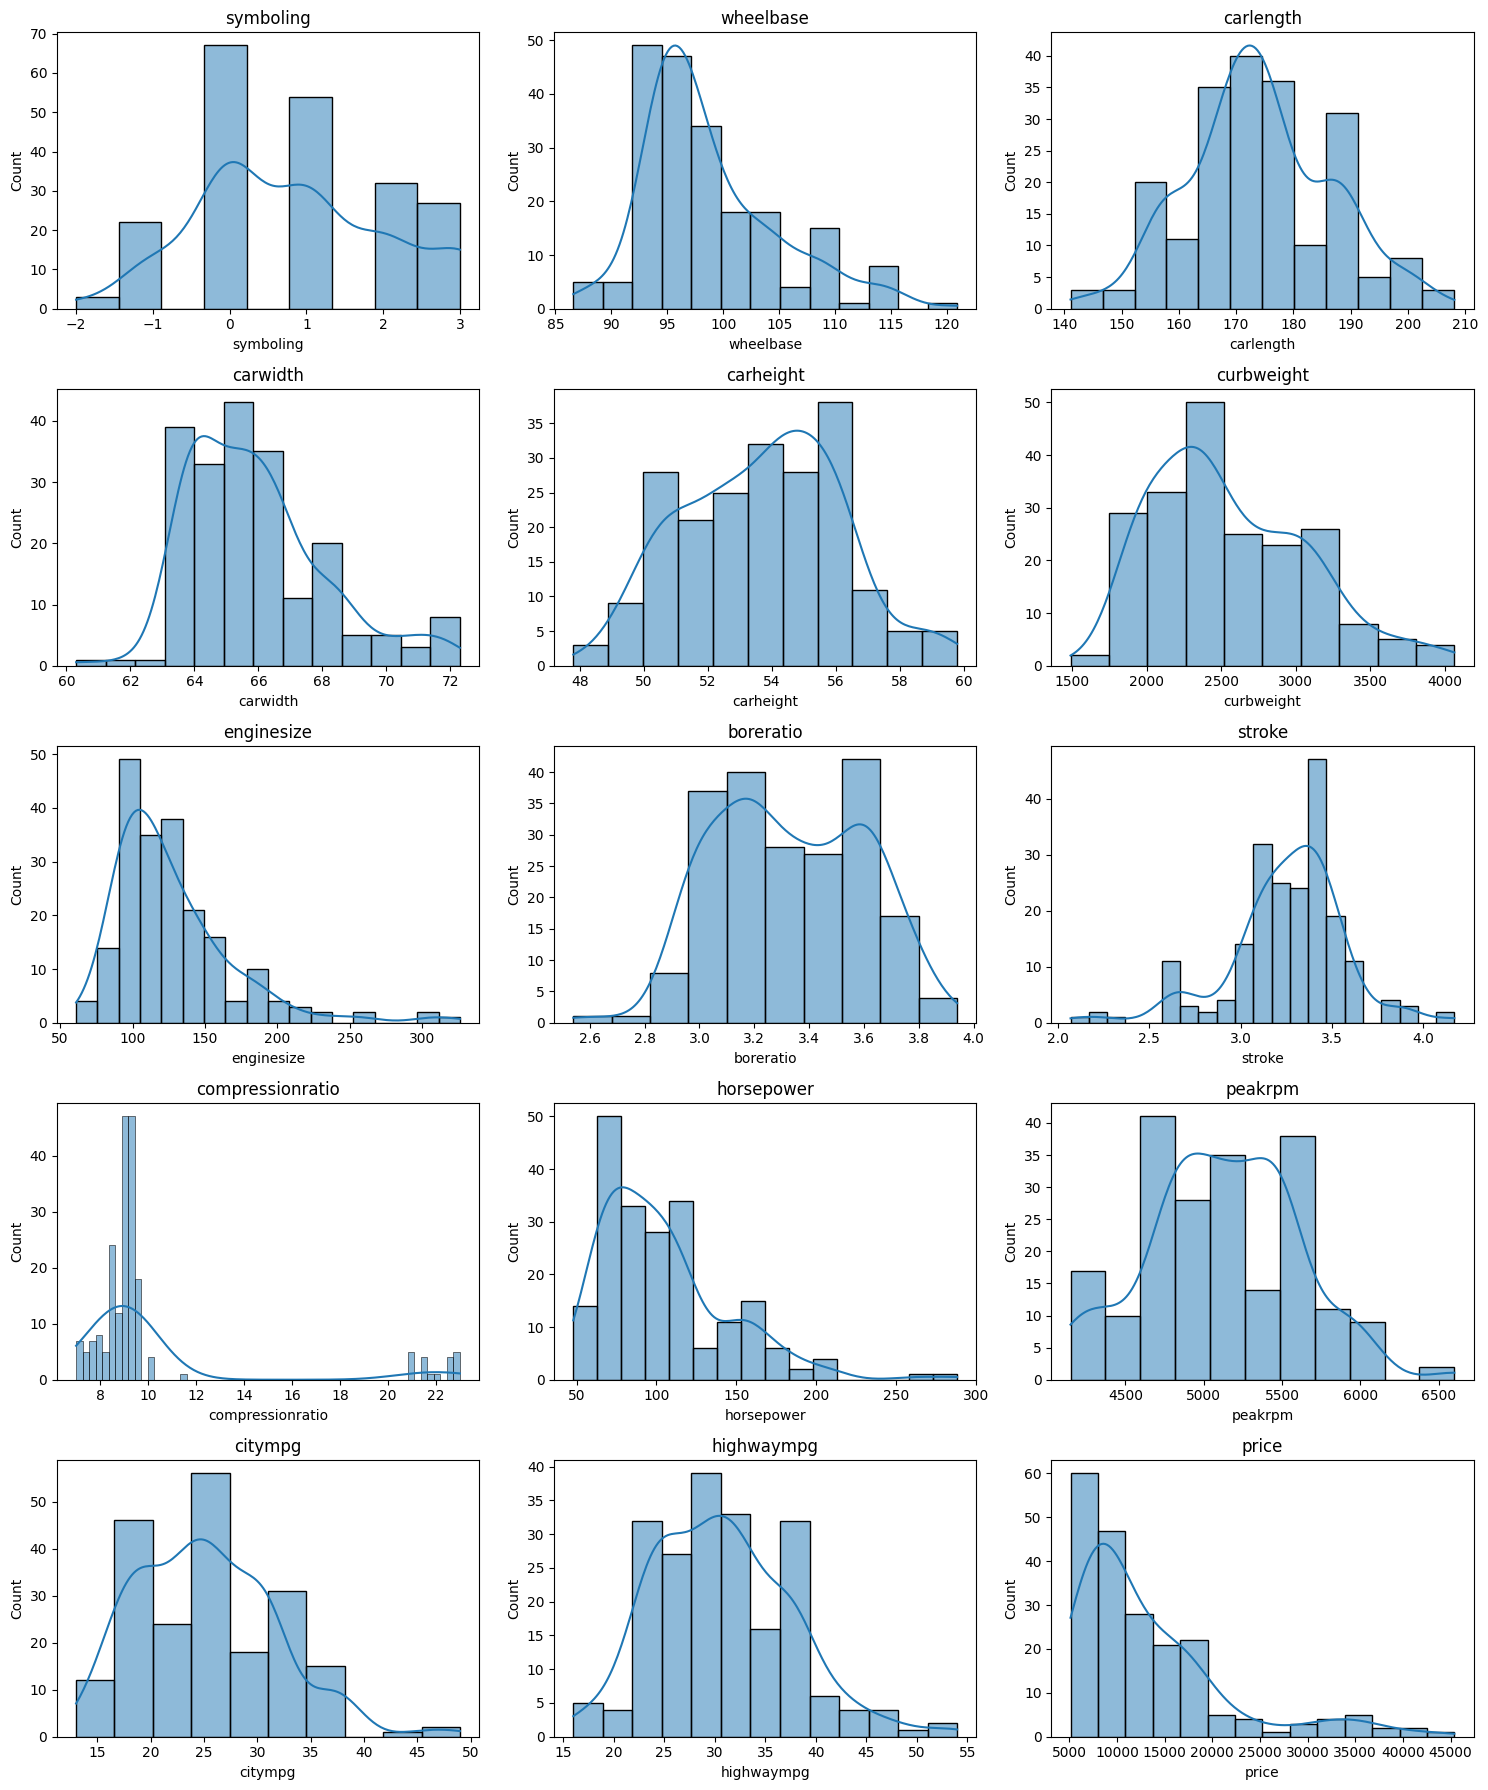

In [43]:
n_cols = 3
n_rows = int(np.ceil(len(numeric_initial) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.6 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, numeric_initial):
    sns.histplot(df_model[col], kde=True, ax=ax)
    ax.set_title(col)

for ax in axes[len(numeric_initial):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Аналіз показав, що найбільшу додатну асиметрію мають compressionratio, enginesize, price та horsepower. Це свідчить про нерівномірність їхніх розподілів і доцільність подальшого перетворення числових ознак для зменшення асиметрії.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [44]:
X = df_model.drop(columns="price")
y = df_model["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

id_train = ids.loc[X_train.index]
id_test = ids.loc[X_test.index]

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (164, 24) Test: (41, 24)


Дані розділено на навчальну (164 записи) та тестову (41 запис) вибірки у співвідношенні 80/20. Використання random_state=42 забезпечує відтворюваність результатів, а окреме збереження ідентифікаторів дозволяє пов'язати прогнози з автомобілями.

## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [45]:
continuous_cols = [
    c for c in X_train.select_dtypes(include=np.number).columns
    if c != "symboling"
]

q1 = X_train[continuous_cols].quantile(0.25)

q3 = X_train[continuous_cols].quantile(0.75)

iqr = q3 - q1

lower_bounds = q1 - 1.5 * iqr

upper_bounds = q3 + 1.5 * iqr

outlier_counts = (
    (X_train[continuous_cols].lt(lower_bounds)) |
    (X_train[continuous_cols].gt(upper_bounds))
).sum().sort_values(ascending=False)

display(outlier_counts.to_frame("potential_outliers_train"))

X_train = X_train.copy()
X_test = X_test.copy()

X_train[continuous_cols] = X_train[continuous_cols].clip(
    lower=lower_bounds,
    upper=upper_bounds,
    axis=1
)

X_test[continuous_cols] = X_test[continuous_cols].clip(
    lower=lower_bounds,
    upper=upper_bounds,
    axis=1
)

,potential_outliers_train
compressionratio,20
stroke,16
carwidth,10
horsepower,7
enginesize,7
wheelbase,6
peakrpm,2
highwaympg,1
boreratio,1
curbweight,0


Методом IQR виявлено потенційні викиди, найбільше — в ознаках compressionratio, stroke та carwidth. Для їх обробки використано обмеження крайніх значень, що дозволило зберегти всі спостереження. Межі визначено лише за навчальною вибіркою.

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


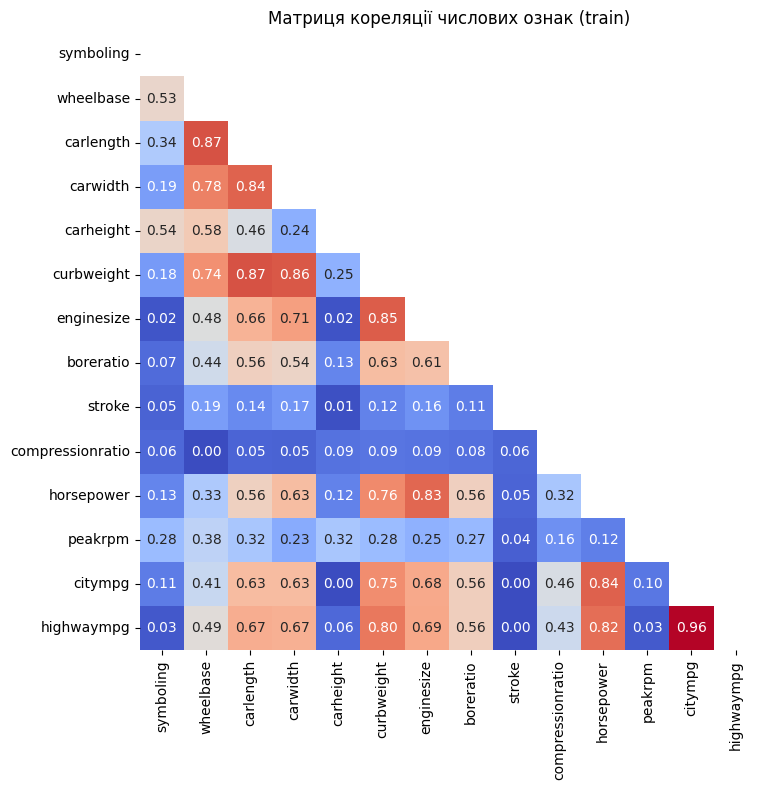

Сильно корельовані пари (|r| > 0.85):
carlength - curbweight: 0.866
carwidth - curbweight: 0.858
citympg - highwaympg: 0.964
wheelbase - carlength: 0.867
Ознаки для видалення: ['carlength', 'carwidth', 'citympg']


In [46]:
numeric_train_cols = X_train.select_dtypes(include=np.number).columns

corr = X_train[numeric_train_cols].corr().abs()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    cmap="coolwarm",
    annot=True,
    fmt=".2f",
    mask=np.triu(np.ones_like(corr, dtype=bool)),
    square=True,
    cbar=False
)

plt.title("Матриця кореляції числових ознак (train)")
plt.tight_layout()
plt.show()

target_corr = pd.concat(
    [
        X_train[numeric_train_cols],
        y_train.rename("price")
    ],
    axis=1
).corr(numeric_only=True)["price"].abs()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

pairs = []

for col in upper.columns:
    for row in upper.index[upper[col] > 0.85]:
        pairs.append(
            (row, col, upper.loc[row, col])
        )

pairs.sort(
    key=lambda x: max(target_corr[x[0]], target_corr[x[1]]),
    reverse=True
)

features_to_drop = set()

for a, b, r in pairs:
    if a in features_to_drop or b in features_to_drop:
        continue

    if target_corr[a] < target_corr[b]:
        features_to_drop.add(a)
    else:
        features_to_drop.add(b)

print("Сильно корельовані пари (|r| > 0.85):")
for a, b, r in pairs:
    print(f"{a} - {b}: {r:.3f}")

print("Ознаки для видалення:", sorted(features_to_drop))

X_train = X_train.drop(
    columns=list(features_to_drop)
)

X_test = X_test.drop(
    columns=list(features_to_drop)
)

Кореляційний аналіз виявив 4 пари числових ознак із сильним зв'язком (|r| > 0.85). Для зменшення мультиколінеарності з урахуванням зв'язку з цільовою змінною price було видалено ознаки carlength, carwidth та citympg. Це дозволило зменшити надлишковість даних, зберігши більш інформативні ознаки для подальшого моделювання.


## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [48]:
continuous_cols = [
    c for c in X_train.select_dtypes(include=np.number).columns
    if c != "symboling"
]

ordinal_numeric_cols = [
    c for c in X_train.select_dtypes(include=np.number).columns
    if c == "symboling"
]

categorical_cols = (
    X_train
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)

numeric_pipeline = Pipeline(steps=[
    ("power", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),
    ("scaler", StandardScaler())
])

ordinal_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
    ("continuous", numeric_pipeline, continuous_cols),
    ("ordinal", ordinal_pipeline, ordinal_numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

Для різних типів ознак створено окремі конвеєри передобробки, об'єднані за допомогою ColumnTransformer. Такий підхід забезпечує послідовне перетворення даних і дозволяє навчати параметри передобробки лише на навчальній вибірці.

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [49]:
skewness_before = X_train[continuous_cols].skew()

num_check = clone(numeric_pipeline)

num_train_transformed = pd.DataFrame(
    num_check.fit_transform(
        X_train[continuous_cols]
    ),
    columns=continuous_cols,
    index=X_train.index
)

skewness_after = num_train_transformed.skew()

skewness_comparison = pd.DataFrame({
    "skewness_before": skewness_before,
    "skewness_after": skewness_after
}).sort_values(
    by="skewness_before",
    key=np.abs,
    ascending=False
)

display(skewness_comparison)

print(
    "Середня абсолютна асиметрія до трансформації:",
    round(skewness_before.abs().mean(), 4)
)

print(
    "Середня абсолютна асиметрія після трансформації:",
    round(skewness_after.abs().mean(), 4)
)

,skewness_before,skewness_after
enginesize,0.962394,0.044834
wheelbase,0.935764,0.020429
horsepower,0.850735,0.066280
curbweight,0.712433,0.049894
stroke,-0.397600,0.015846
highwaympg,0.243761,-0.012188
boreratio,0.062963,-0.005941
compressionratio,0.055710,0.004872
peakrpm,0.039773,-0.003589
carheight,0.028154,-0.005170


Середня абсолютна асиметрія до трансформації: 0.4289
Середня абсолютна асиметрія після трансформації: 0.0229


Після застосування перетворення Yeo–Johnson середня абсолютна асиметрія числових ознак зменшилася з 0.4289 до 0.0229. Значення асиметрії всіх ознак наблизилися до нуля, що свідчить про ефективність трансформації та наближення розподілів до симетричних.


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [50]:
estimators = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(
        alpha=1.0
    ),
    "Lasso": Lasso(
        alpha=1.0,
        max_iter=20000
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=500,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),
    "SVR": SVR()
}

models = {
    name: Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])

    for name, estimator in estimators.items()
}

Створено шість регресійних моделей із використанням єдиного механізму передобробки даних. Це забезпечує однакові умови навчання та дозволяє коректно порівняти ефективність різних алгоритмів прогнозування ціни автомобілів.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [53]:
results = []

predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "R²": r2_score(
            y_test,
            y_pred
        ),
        "MAE": mean_absolute_error(
            y_test,
            y_pred
        ),
        "MSE": mean_squared_error(
            y_test,
            y_pred
        ),
        "MAPE, %": mean_absolute_percentage_error(
            y_test,
            y_pred
        ) * 100
    })

results_df = (
    pd.DataFrame(results)
    .sort_values(
        "R²",
        ascending=False
    )
    .reset_index(drop=True)
)

display(results_df)

,Model,R²,MAE,MSE,"MAPE, %"
0,Random Forest,0.956608,1275.654634,3.425507e+06,9.348750
1,Gradient Boosting,0.935979,1637.748995,5.054054e+06,11.359246
2,Linear Regression,0.880073,2062.334152,9.467543e+06,15.566550
3,Lasso,0.877881,2043.455885,9.640549e+06,14.919870
4,Ridge,0.851334,2336.034579,1.173632e+07,18.552217
5,SVR,-0.099741,5696.349340,8.681798e+07,36.021091


Порівняння шести регресійних моделей показало, що найкращі результати отримано за допомогою Random Forest (R² = 0.9566, MAPE = 9.35%), яка продемонструвала найменші похибки прогнозування. Дещо нижчу точність показала Gradient Boosting, тоді як найгірші результати отримано для SVR (R² = -0.0997). Отже, ансамблеві методи виявилися найефективнішими для прогнозування ціни автомобілів на цьому наборі даних.


In [58]:
overfit_results = []

for name, model in models.items():
    overfit_results.append({
        "Model": name,
        "R² train": r2_score(
            y_train, model.predict(X_train)
        ),
        "R² test": r2_score(
            y_test, model.predict(X_test)
        )
    })

display(pd.DataFrame(overfit_results))

,Model,R² train,R² test
0,Linear Regression,0.961031,0.880073
1,Ridge,0.949861,0.851334
2,Lasso,0.960849,0.877881
3,Random Forest,0.985697,0.956608
4,Gradient Boosting,0.993117,0.935979
5,SVR,-0.108244,-0.099741


Random Forest не лише показала найкращу точність, а й продемонструвала найменше зниження R² між навчальною та тестовою вибірками. Це додатковий аргумент на користь вибору цієї моделі.

## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Прогнозування ціни автомобіля належить до задач регресії, оскільки цільова змінна price є неперервною числовою величиною.

Класифікаційні моделі, зокрема Logistic Regression, призначені для визначення ймовірності належності об'єкта до певного класу, а не для безпосереднього прогнозування числових значень. Тому вони не підходять для цієї задачі без перетворення ціни на категорії, що призвело б до втрати точності її визначення.

Використані в роботі моделі Linear Regression, Ridge, Lasso, Random Forest Regressor, Gradient Boosting Regressor та SVR призначені для розв'язання регресійних задач. Вони дозволяють прогнозувати конкретне числове значення ціни автомобіля на основі його характеристик.


## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


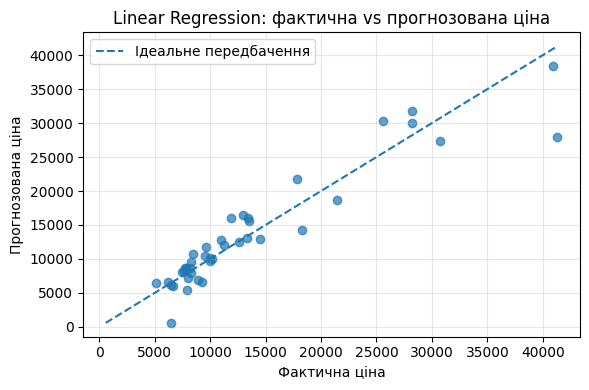

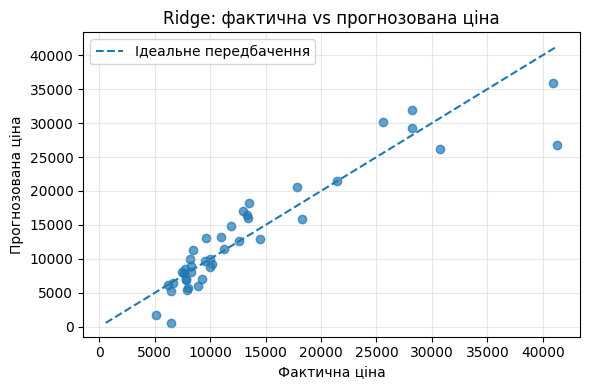

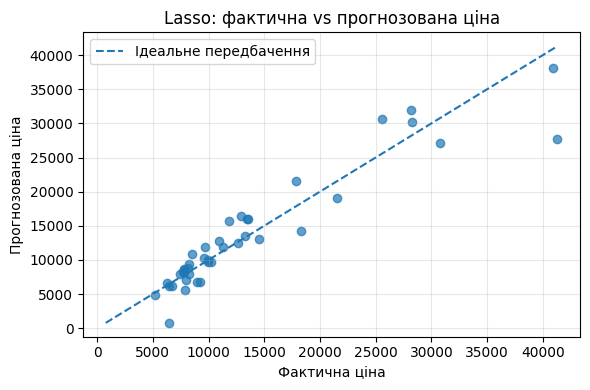

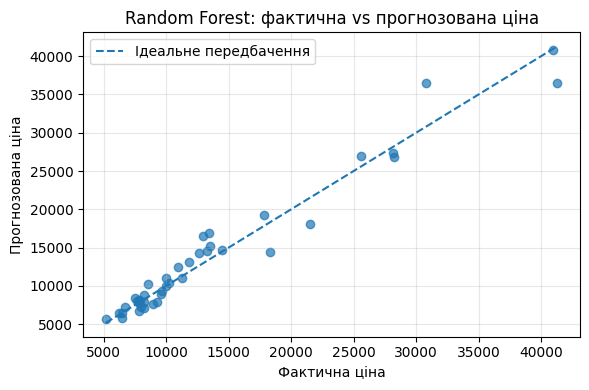

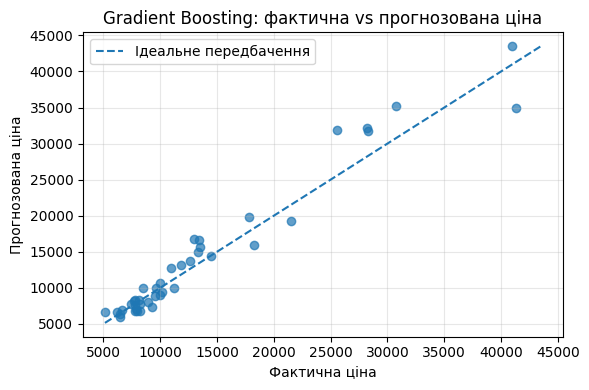

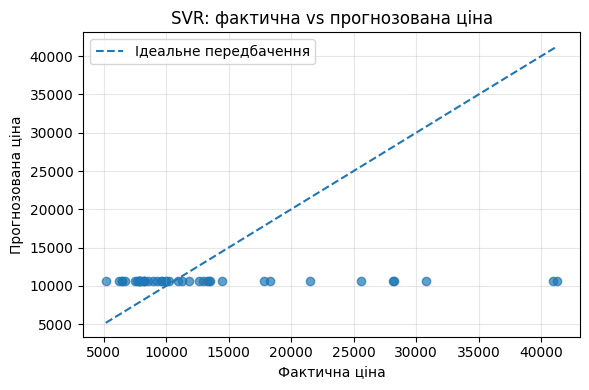

In [54]:
y_true = y_test.to_numpy()

for name, y_pred in predictions.items():
    y_pred = np.asarray(y_pred).ravel()

    lo = min(y_true.min(), y_pred.min())
    hi = max(y_true.max(), y_pred.max())

    plt.figure(figsize=(6, 4))

    plt.scatter(y_true, y_pred, alpha=0.7)

    plt.plot(
        [lo, hi],
        [lo, hi],
        "--",
        label="Ідеальне передбачення"
    )

    plt.xlabel("Фактична ціна")
    plt.ylabel("Прогнозована ціна")
    plt.title(f"{name}: фактична vs прогнозована ціна")

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

Візуальне порівняння прогнозів показало, що найточніші результати отримано для моделей Random Forest та Gradient Boosting, прогнозовані значення яких найближчі до лінії ідеального передбачення. Лінійні моделі демонструють більші відхилення, а найгірший результат спостерігається у SVR. Це узгоджується з показниками якості, отриманими в попередньому завданні. Найбільші відхилення від ідеального прогнозу спостерігаються переважно для автомобілів із високою вартістю, що свідчить про складність точного прогнозування в цьому ціновому сегменті.


## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [57]:
rf_model = models["Random Forest"]

sample_idx = X_test.sample(
    n=min(10, len(X_test)),
    random_state=42
).index

sample_pred = rf_model.predict(
    X_test.loc[sample_idx]
)

sample_rf = pd.DataFrame({
    "car_ID": id_test.loc[sample_idx].to_numpy(),
    "Actual price": y_test.loc[sample_idx].to_numpy(),
    "Predicted price (RF)": sample_pred
})

sample_rf["Absolute error"] = (
    sample_rf["Actual price"]
    - sample_rf["Predicted price (RF)"]
).abs()

sample_rf["Absolute percentage error, %"] = (
    sample_rf["Absolute error"]
    / sample_rf["Actual price"]
    * 100
)

display(sample_rf)

,car_ID,Actual price,Predicted price (RF),Absolute error,"Absolute percentage error, %"
0,26,6692.0,7290.443000,598.443000,8.942663
1,176,9988.0,11000.579333,1012.579333,10.137959
2,148,10198.0,10426.323167,228.323167,2.238901
3,17,41315.0,36454.824000,4860.176000,11.763708
4,69,28248.0,26839.915000,1408.085000,4.984725
5,147,7463.0,8459.923000,996.923000,13.358207
6,144,9960.0,9952.154500,7.845500,0.078770
7,85,14489.0,14625.318000,136.318000,0.940838
8,195,12940.0,16444.106000,3504.106000,27.079645
9,160,7788.0,7734.074667,53.925333,0.692416


Прогнозування ціни 10 випадково обраних автомобілів за допомогою Random Forest показало достатньо високу точність моделі. Середня абсолютна відсоткова похибка становить 8,02%, при цьому найменша похибка — 0,08%, а найбільша — 27,08% (автомобіль №195). Отже, модель загалом забезпечує точні прогнози, хоча для окремих автомобілів спостерігаються значні відхилення від фактичної ціни.


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


У ході лабораторної роботи було проведено аналіз і попередню обробку даних про автомобілі, побудовано та порівняно шість регресійних моделей для прогнозування їхньої вартості. Обробка викидів, відбір корельованих ознак, кодування категоріальних даних і масштабування забезпечили підготовку даних до моделювання. Застосування перетворення Yeo–Johnson дозволило зменшити середню абсолютну асиметрію числових ознак із 0.4289 до 0.0229.

За результатами оцінювання найкращу якість продемонструвала модель **Random Forest** (R² = 0.9566, MAE = 1275.65, MSE ≈ 3.43 млн, MAPE = 9.35%). Дещо нижчі показники отримано для Gradient Boosting (R² = 0.9360, MAPE = 11.36%). Моделі Linear Regression, Lasso та Ridge показали задовільні результати з R² від 0.8513 до 0.8801. Найгіршою виявилася SVR (R² = -0.0997, MAPE = 36.02%). Отже, ансамблеві методи продемонстрували найвищу точність прогнозування.

Візуальне порівняння підтвердило перевагу Random Forest та Gradient Boosting, хоча для окремих автомобілів спостерігалися значні відхилення. Для 10 випадково обраних автомобілів середня абсолютна відсоткова похибка Random Forest становила 8.02%, а максимальна — 27.08%.

Порівняння R² на навчальній і тестовій вибірках показало, що Random Forest має найменше зниження якості (з 0.9857 до 0.9566), що не свідчить про виражене перенавчання. Для Gradient Boosting та лінійних моделей спостерігається помітніший розрив між результатами, тоді як SVR демонструє низьку якість на обох вибірках.

Таким чином, **Random Forest виявилася найефективнішою моделлю** для прогнозування ціни автомобілів у межах проведеного дослідження, поєднуючи високу точність і хорошу здатність до узагальнення. Попередня обробка забезпечила зменшення асиметрії та підготовку різних типів ознак, проте її безпосередній вплив на точність моделей потребує окремого дослідження.


## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
